# HybridGNNVAEGRU

 GNN-VAE-GRU, OmniAnomaly, GANomaly and Temporal Graph Network experiments.

In [1]:
!pip install torch_geometric

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 20.0 MB/s  0:00:00


In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv('creditcard.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3973 entries, 0 to 3972
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    3973 non-null   int64  
 1   V1      3973 non-null   float64
 2   V2      3973 non-null   float64
 3   V3      3973 non-null   float64
 4   V4      3973 non-null   float64
 5   V5      3973 non-null   float64
 6   V6      3973 non-null   float64
 7   V7      3973 non-null   float64
 8   V8      3973 non-null   float64
 9   V9      3973 non-null   float64
 10  V10     3973 non-null   float64
 11  V11     3973 non-null   float64
 12  V12     3973 non-null   float64
 13  V13     3973 non-null   float64
 14  V14     3973 non-null   float64
 15  V15     3973 non-null   float64
 16  V16     3973 non-null   float64
 17  V17     3973 non-null   float64
 18  V18     3973 non-null   float64
 19  V19     3973 non-null   float64
 20  V20     3973 non-null   float64
 21  V21     3973 non-null   float64
 22  

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import random
import numpy as np
import pandas as pd
from torch_geometric.nn import GATConv, GCNConv, GraphConv
from torch_geometric.data import Data, DataLoader
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, average_precision_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
from torch.optim.lr_scheduler import ReduceLROnPlateau
import time

# Seed setting for reproducibility
def set_seed(seed=42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

# Attention module for feature enhancement
class FeatureAttention(nn.Module):
    def __init__(self, in_features):
        super(FeatureAttention, self).__init__()
        self.attention = nn.Sequential(
            nn.Linear(in_features, in_features // 2),
            nn.LeakyReLU(0.2),
            nn.Linear(in_features // 2, in_features),
            nn.Sigmoid()
        )

    def forward(self, x):
        att_weights = self.attention(x)
        return x * att_weights

# Improved Hybrid GNN-VAE-GRU Model with additional components
class EnhancedHybridGNNVAEGRU(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, latent_dim, heads=4, dropout=0.3):
        super(EnhancedHybridGNNVAEGRU, self).__init__()

        # Feature attention
        self.feature_attention = FeatureAttention(in_channels)

        # Multi-layer GNN with residual connections
        self.conv1 = GATConv(in_channels, hidden_channels, heads=heads, dropout=dropout, edge_dim=1)
        self.conv2 = GCNConv(hidden_channels * heads, hidden_channels * heads)
        self.conv3 = GraphConv(hidden_channels * heads, out_channels)

        # Normalization layers
        self.norm1 = nn.LayerNorm(hidden_channels * heads)
        self.norm2 = nn.LayerNorm(hidden_channels * heads)
        self.norm3 = nn.LayerNorm(out_channels)

        # VAE components
        self.fc_mu = nn.Sequential(
            nn.Linear(out_channels, latent_dim * 2),
            nn.LeakyReLU(0.2),
            nn.Dropout(dropout),
            nn.Linear(latent_dim * 2, latent_dim)
        )

        self.fc_logvar = nn.Sequential(
            nn.Linear(out_channels, latent_dim * 2),
            nn.LeakyReLU(0.2),
            nn.Dropout(dropout),
            nn.Linear(latent_dim * 2, latent_dim)
        )

        # Bidirectional GRU for temporal modeling
        self.gru = nn.GRU(
            latent_dim,
            latent_dim,
            num_layers=3,
            batch_first=True,
            bidirectional=True,
            dropout=dropout
        )

        # MLP for final prediction
        self.mlp = nn.Sequential(
            nn.Linear(latent_dim * 2, latent_dim),
            nn.LeakyReLU(0.2),
            nn.Dropout(dropout),
            nn.Linear(latent_dim, latent_dim // 2),
            nn.LeakyReLU(0.2),
            nn.Linear(latent_dim // 2, 1)
        )

        # Auxiliary classifier
        self.aux_classifier = nn.Sequential(
            nn.Linear(out_channels, latent_dim),
            nn.LeakyReLU(0.2),
            nn.Dropout(dropout),
            nn.Linear(latent_dim, 1)
        )

        # Reconstruction decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, latent_dim * 2),
            nn.LeakyReLU(0.2),
            nn.Dropout(dropout),
            nn.Linear(latent_dim * 2, out_channels),
            nn.LeakyReLU(0.2),
            nn.Linear(out_channels, in_channels)
        )

    def encode(self, x, edge_index, edge_attr):
        # Apply feature attention
        x = self.feature_attention(x)

        # First graph convolution
        x1 = self.norm1(F.leaky_relu(self.conv1(x, edge_index, edge_attr), 0.2))

        # Second graph convolution with residual connection
        x2 = self.norm2(F.leaky_relu(self.conv2(x1, edge_index), 0.2) + x1)

        # Third graph convolution
        x3 = self.norm3(F.leaky_relu(self.conv3(x2, edge_index), 0.2))

        # VAE encoding
        mu = self.fc_mu(x3)
        logvar = self.fc_logvar(x3)

        return x3, mu, logvar

    def reparameterize(self, mu, logvar):
        if self.training:
            std = torch.exp(0.5 * logvar)
            eps = torch.randn_like(std)
            return mu + eps * std
        else:
            return mu

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x, edge_index, edge_attr, h=None):
        # Encode
        x_encoded, mu, logvar = self.encode(x, edge_index, edge_attr)

        # Auxiliary prediction directly from encoded features
        aux_out = self.aux_classifier(x_encoded)

        # Reparameterize
        z = self.reparameterize(mu, logvar)

        # Decode for reconstruction
        x_recon = self.decode(z)

        # GRU processing
        z_sequence = z.unsqueeze(1)  # Add sequence dimension

        if h is None:
            # Initialize hidden state if not provided
            h = torch.zeros(2 * 3, z.size(0), mu.size(1), device=x.device)  # 2 for bidirectional, 3 for num_layers

        gru_out, h = self.gru(z_sequence, h)

        # Final MLP prediction
        main_out = self.mlp(gru_out.squeeze(1))

        return main_out, aux_out, x_recon, h, mu, logvar

def enhanced_loss_function(main_pred, aux_pred, x_recon, x_orig, target, mu, logvar,
                           gamma=2.0, alpha=0.25, recon_weight=0.2, kld_weight=0.1, aux_weight=0.3):
    # Binary cross entropy with logits for main prediction with focal loss
    pt = torch.sigmoid(main_pred.squeeze())
    pt = torch.where(target.float() == 1, pt, 1-pt)
    focal_weight = alpha * torch.pow(1 - pt, gamma)
    # Detach focal_weight to make it non-differentiable
    focal_weight = focal_weight.detach()
    main_bce = F.binary_cross_entropy_with_logits(
        main_pred.squeeze(),
        target.float(),
        weight=focal_weight,
        reduction='mean'
    )

    # Auxiliary prediction loss
    aux_bce = F.binary_cross_entropy_with_logits(
        aux_pred.squeeze(),
        target.float(),
        weight=focal_weight,
        reduction='mean'
    )

    # Reconstruction loss
    recon_loss = F.mse_loss(x_recon, x_orig, reduction='mean')

    # KL divergence
    kld = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())

    # Total loss
    total_loss = main_bce + aux_weight * aux_bce + recon_weight * recon_loss + kld_weight * kld

    return total_loss, main_bce, aux_bce, recon_loss, kld

# Load and preprocess data with improved feature engineering
def load_creditcard_data(path='creditcard.csv'):
    """Load raw rows and deterministic per-row features; fit NO scalers here.

    All learned preprocessing is fitted exclusively to the training split.
    """
    print("Loading raw credit card records...")
    df = pd.read_csv(path).dropna().copy()
    labels = df['Class'].to_numpy(dtype=int)
    df['NormTime'] = df['Time']  # normalized later using train-only scaler
    df['Hour'] = (df['Time'] / 3600) % 24
    df['Hour_sin'] = np.sin(2 * np.pi * df['Hour'] / 24)
    df['Hour_cos'] = np.cos(2 * np.pi * df['Hour'] / 24)
    df['V1_V3'] = df['V1'] * df['V3']
    df['V4_V12'] = df['V4'] * df['V12']
    df['V14_V17'] = df['V14'] * df['V17']
    df.drop(columns=['Time', 'Hour', 'Class'], inplace=True)
    return df.to_numpy(dtype=np.float32), labels, list(df.columns)


def fit_train_preprocessing(X_train, X_val, X_test, feature_names):
    """Train-only RobustScaler for Amount, then train-only StandardScaler."""
    amount_index = feature_names.index('Amount')
    robust = RobustScaler().fit(X_train[:, [amount_index]])
    def transform_amount(X):
        out = X.copy()
        out[:, amount_index] = robust.transform(X[:, [amount_index]]).ravel()
        return out
    train = transform_amount(X_train)
    val = transform_amount(X_val)
    test = transform_amount(X_test)
    scaler = StandardScaler().fit(train)
    return (scaler.transform(train).astype(np.float32),
            scaler.transform(val).astype(np.float32),
            scaler.transform(test).astype(np.float32),
            robust, scaler)

# Create dynamic graph from features using distance and similarity
def create_graph_from_batch(features, labels, k=10, epsilon=0.5):
    # Compute cosine similarity
    sim = cosine_similarity(features)

    # Create edges based on similarity threshold and k-nearest neighbors
    edge_index = []
    edge_weights = []

    for i in range(sim.shape[0]):
        # Get indices of top-k similar nodes
        neighbors_idx = sim[i].argsort()[-k-1:-1]

        for j in neighbors_idx:
            # Add edge if similarity is above threshold
            if sim[i, j] > epsilon:
                edge_index.append([i, j])
                edge_weights.append([sim[i, j]])  # Use similarity as edge weight

    # If no edges above threshold, fall back to basic k-nn
    if len(edge_index) == 0:
        for i in range(sim.shape[0]):
            neighbors_idx = sim[i].argsort()[-k-1:-1]
            for j in neighbors_idx:
                edge_index.append([i, j])
                edge_weights.append([sim[i, j]])

    edge_index = torch.tensor(edge_index, dtype=torch.long).t().contiguous()
    edge_attr = torch.tensor(edge_weights, dtype=torch.float)
    x = torch.tensor(features, dtype=torch.float)

    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr), torch.tensor(labels)

# Compute anomaly scores with ensemble approach
def compute_anomaly_scores(main_pred, aux_pred, recon_error, mu, logvar, alpha=0.6, beta=0.2, gamma=0.2):
    # Convert predictions to probabilities
    main_prob = torch.sigmoid(main_pred).squeeze()
    aux_prob = torch.sigmoid(aux_pred).squeeze()

    # Compute reconstruction probability (1 - normalized error)
    recon_prob = 1 - torch.nn.functional.normalize(recon_error, p=2, dim=0)

    # Compute KL divergence
    kl_div = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1)
    kl_prob = 1 - torch.nn.functional.normalize(kl_div, p=2, dim=0)

    # Ensemble score
    ensemble_score = alpha * main_prob + beta * aux_prob + gamma * (recon_prob + kl_prob) / 2

    return ensemble_score.detach().cpu().numpy()

# Enhanced evaluation function
def evaluate_model(threshold, main_pred, aux_pred, x_recon, x_orig, mu, logvar, true_labels):
    # Compute reconstruction error
    recon_error = torch.mean((x_recon - x_orig).pow(2), dim=1)

    # Calculate ensemble anomaly scores
    anomaly_scores = compute_anomaly_scores(main_pred, aux_pred, recon_error, mu, logvar)

    # Binary predictions based on threshold
    preds = (anomaly_scores > threshold).astype(int)

    # Calculate metrics
    precision = precision_score(true_labels, preds, zero_division=0)
    recall = recall_score(true_labels, preds, zero_division=0)
    f1 = f1_score(true_labels, preds, zero_division=0)
    auc = roc_auc_score(true_labels, anomaly_scores)
    avg_precision = average_precision_score(true_labels, anomaly_scores)

    return precision, recall, f1, auc, avg_precision, anomaly_scores

# Visualize latent space
# def visualize_latent_space(mu, labels, save_path='latent_space_visualization.png'):
#     # Apply t-SNE for dimensionality reduction
#     tsne = TSNE(n_components=2, random_state=42)
#     z_tsne = tsne.fit_transform(mu)

#     # Create scatter plot
#     plt.figure(figsize=(10, 8))
#     scatter = plt.scatter(z_tsne[:, 0], z_tsne[:, 1], c=labels, cmap='coolwarm', alpha=0.7)
#     plt.colorbar(scatter)
#     plt.title('t-SNE Visualization of Latent Space')
#     plt.xlabel('t-SNE Component 1')
#     plt.ylabel('t-SNE Component 2')
#     plt.savefig(save_path)
#     plt.close()

# Enhanced training function with early stopping and learning rate scheduling
def train(model, optimizer, features, labels, batch_size=128, epochs=50, patience=10, device='cpu'):
    model.train()
    model = model.to(device)

    # Create scheduler for learning rate reduction
    scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

    # Setup early stopping
    best_loss = float('inf')
    no_improve_epochs = 0

    # Training statistics
    train_losses = []

    # Shuffle training rows into disjoint mini-batches (no repeated validation folds).
    rng = np.random.default_rng(42)

    print(f"Starting training for {epochs} epochs...")
    start_time = time.time()

    for epoch in range(epochs):
        epoch_loss = 0.0
        epoch_main_loss = 0.0
        epoch_aux_loss = 0.0
        epoch_recon_loss = 0.0
        epoch_kld_loss = 0.0
        batch_count = 0

        for batch_idx in np.array_split(rng.permutation(len(labels)),
                                         max(1, int(np.ceil(len(labels) / batch_size)))):
            if len(batch_idx) < 3:
                continue
            batch_features = features[batch_idx]
            batch_labels = labels[batch_idx]

            # Create graph data
            graph_data, true_labels = create_graph_from_batch(batch_features, batch_labels)

            # Move data to device
            graph_data = graph_data.to(device)
            true_labels = true_labels.to(device)

            # Zero gradients
            optimizer.zero_grad()

            # Forward pass
            main_out, aux_out, x_recon, _, mu, logvar = model(
                graph_data.x, graph_data.edge_index, graph_data.edge_attr
            )

            # Compute loss
            loss, main_loss, aux_loss, recon_loss, kld = enhanced_loss_function(
                main_out, aux_out, x_recon, graph_data.x, true_labels, mu, logvar
            )

            # Backward pass and optimize
            loss.backward()

            # Gradient clipping to prevent exploding gradients
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

            optimizer.step()

            # Accumulate losses
            epoch_loss += loss.item()
            epoch_main_loss += main_loss.item()
            epoch_aux_loss += aux_loss.item()
            epoch_recon_loss += recon_loss.item()
            epoch_kld_loss += kld.item()
            batch_count += 1

        # Calculate average losses
        avg_epoch_loss = epoch_loss / batch_count if batch_count > 0 else 0
        avg_main_loss = epoch_main_loss / batch_count if batch_count > 0 else 0
        avg_aux_loss = epoch_aux_loss / batch_count if batch_count > 0 else 0
        avg_recon_loss = epoch_recon_loss / batch_count if batch_count > 0 else 0
        avg_kld_loss = epoch_kld_loss / batch_count if batch_count > 0 else 0

        # Update learning rate
        scheduler.step(avg_epoch_loss)

        # Print progress
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"Epoch {epoch + 1}/{epochs}, Avg Loss: {avg_epoch_loss:.4f}, "
                  f"Main Loss: {avg_main_loss:.4f}, Aux Loss: {avg_aux_loss:.4f}, "
                  f"Recon Loss: {avg_recon_loss:.4f}, KLD: {avg_kld_loss:.4f}")

        train_losses.append(avg_epoch_loss)

        # Check for early stopping
        if avg_epoch_loss < best_loss:
            best_loss = avg_epoch_loss
            torch.save(model.state_dict(), 'best_model.pt')
            no_improve_epochs = 0
        else:
            no_improve_epochs += 1
            if no_improve_epochs >= patience:
                print(f"Early stopping at epoch {epoch + 1}")
                break

    training_time = time.time() - start_time
    print(f"Training completed in {training_time:.2f} seconds")

    # Load the best model
    model.load_state_dict(torch.load('best_model.pt', map_location=device, weights_only=True))
    return model, train_losses

# Leakage-safe inference: threshold is chosen on validation, then frozen for test.
def collect_scores(model, features, labels, batch_size=128, device='cpu'):
    model.eval()
    model = model.to(device)
    scores = []
    actual = []
    with torch.no_grad():
        for start in range(0, len(labels), batch_size):
            end = min(start + batch_size, len(labels))
            if end - start < 3:
                continue
            graph, _ = create_graph_from_batch(features[start:end], labels[start:end])
            graph = graph.to(device)
            main, aux, recon, _, mu, logvar = model(graph.x, graph.edge_index, graph.edge_attr)
            recon_error = torch.mean((recon - graph.x).pow(2), dim=1)
            score = compute_anomaly_scores(main, aux, recon_error, mu, logvar)
            scores.extend(np.atleast_1d(score).tolist())
            actual.extend(labels[start:end].tolist())
    if not scores:
        raise ValueError('No valid evaluation batches.')
    return np.asarray(scores), np.asarray(actual)


def choose_threshold(validation_scores, validation_labels):
    candidates = np.unique(np.quantile(validation_scores, np.linspace(0.01, 0.99, 99)))
    # Decision based EXCLUSIVELY on validation labels.
    performances = [f1_score(validation_labels, validation_scores >= t,
                             zero_division=0) for t in candidates]
    return float(candidates[int(np.argmax(performances))])


def report_scores(scores, labels, threshold, split_name):
    pred = (scores >= threshold).astype(int)
    result = {
        'precision': float(precision_score(labels, pred, zero_division=0)),
        'recall': float(recall_score(labels, pred, zero_division=0)),
        'f1': float(f1_score(labels, pred, zero_division=0)),
        'roc_auc': float(roc_auc_score(labels, scores)) if len(np.unique(labels)) > 1 else None,
        'pr_auc': float(average_precision_score(labels, scores)) if len(np.unique(labels)) > 1 else None,
        'fraud_rows': int(labels.sum()),
        'rows': int(len(labels)),
        'threshold': float(threshold),
    }
    print(f'\n{split_name}:', result)
    return result


def run_hybrid_experiment(data_path='creditcard.csv', epochs=50):
    set_seed()
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print('Device:', device)
    features, labels, feature_names = load_creditcard_data(data_path)
    X_trainval, X_test, y_trainval, y_test = train_test_split(
        features, labels, test_size=0.20, random_state=42, stratify=labels)
    X_train, X_val, y_train, y_val = train_test_split(
        X_trainval, y_trainval, test_size=0.25, random_state=42, stratify=y_trainval)
    X_train, X_val, X_test, robust, scaler = fit_train_preprocessing(
        X_train, X_val, X_test, feature_names)
    print('Train/validation/test:', len(y_train), len(y_val), len(y_test))
    print('Fraud counts:', int(y_train.sum()), int(y_val.sum()), int(y_test.sum()))

    model_config = dict(in_channels=X_train.shape[1], hidden_channels=64,
                        out_channels=32, latent_dim=16, heads=4, dropout=0.3)
    model = EnhancedHybridGNNVAEGRU(**model_config)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)
    model, losses = train(model, optimizer, X_train, y_train,
                          batch_size=128, epochs=epochs, device=device)
    val_scores, val_labels = collect_scores(model, X_val, y_val, device=device)
    threshold = choose_threshold(val_scores, val_labels)
    validation_metrics = report_scores(val_scores, val_labels, threshold, 'VALIDATION')
    # Only one final test pass. Never tune threshold/hyperparameters on this result.
    test_scores, test_labels = collect_scores(model, X_test, y_test, device=device)
    test_metrics = report_scores(test_scores, test_labels, threshold, 'HELD-OUT TEST')

    # Store state_dict + feature/scaler metadata; no arbitrary pickle model object.
    torch.save({'model_state_dict': {k: v.cpu() for k, v in model.state_dict().items()},
                'model_config': model_config,
                'feature_names': feature_names,
                'amount_index': feature_names.index('Amount'),
                'robust_center': robust.center_.tolist(),
                'robust_scale': robust.scale_.tolist(),
                'standard_mean': scaler.mean_.tolist(),
                'standard_scale': scaler.scale_.tolist(),
                'threshold': threshold,
                'validation_metrics': validation_metrics,
                'test_metrics': test_metrics}, 'fraud_model.pt')
    return model, test_metrics


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [4]:
model, test_metrics = run_hybrid_experiment('creditcard.csv', epochs=50)


Device: cpu
Loading raw credit card records...
Train/validation/test: 9561 3187 3187
Fraud counts: 44 14 15
Starting training for 50 epochs...
Epoch 1/50, Avg Loss: 0.2211, Main Loss: 0.0164, Aux Loss: 0.0074, Recon Loss: 1.0074, KLD: 0.0097
Epoch 5/50, Avg Loss: 0.1750, Main Loss: 0.0011, Aux Loss: 0.0008, Recon Loss: 0.8253, KLD: 0.0856
Epoch 10/50, Avg Loss: 0.1669, Main Loss: 0.0008, Aux Loss: 0.0007, Recon Loss: 0.7854, KLD: 0.0879
Epoch 15/50, Avg Loss: 0.1630, Main Loss: 0.0007, Aux Loss: 0.0005, Recon Loss: 0.7640, KLD: 0.0936
Epoch 20/50, Avg Loss: 0.1625, Main Loss: 0.0008, Aux Loss: 0.0005, Recon Loss: 0.7608, KLD: 0.0945
Epoch 25/50, Avg Loss: 0.1592, Main Loss: 0.0007, Aux Loss: 0.0005, Recon Loss: 0.7432, KLD: 0.0970
Epoch 30/50, Avg Loss: 0.1621, Main Loss: 0.0010, Aux Loss: 0.0007, Recon Loss: 0.7574, KLD: 0.0943
Epoch 35/50, Avg Loss: 0.1581, Main Loss: 0.0007, Aux Loss: 0.0005, Recon Loss: 0.7382, KLD: 0.0959
Epoch 40/50, Avg Loss: 0.1583, Main Loss: 0.0007, Aux Loss:

In [ ]:
# Save the trained Hybrid model using the safe state_dict export in run_hybrid_experiment().
# The original joblib.dump(model) pickled a live torch object and could not be
# loaded by dashboard.py with sklearn-style model.predict().
# Uncomment only AFTER running the experiment above:
# from google.colab import files
# files.download('fraud_model.pt')


In [ ]:
#OmniAnomaly model

In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import random
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

# Fix seeds
def set_seed(seed=42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# Load and preprocess data
def load_creditcard_data(path='creditcard.csv'):
    df = pd.read_csv(path)
    df.dropna(inplace=True)
    df.drop(columns=['Time'], inplace=True)
    # Raw features only: the scaler is fitted on training rows below.
    features = df.drop(columns=['Class']).values
    labels = df['Class'].values.astype(int)
    return features, labels

# Convert features into sequences for OmniAnomaly
def reshape_into_sequences(X, y, seq_len=10):
    num_seqs = len(X) // seq_len
    X = X[:num_seqs * seq_len].reshape(num_seqs, seq_len, -1)
    y = y[:num_seqs * seq_len].reshape(num_seqs, seq_len)
    y_seq = (np.max(y, axis=1) > 0).astype(int)  # label 1 if any fraud in sequence
    return torch.tensor(X, dtype=torch.float32), y_seq

# OmniAnomaly Model
class OmniAnomaly(nn.Module):
    def __init__(self, input_size, hidden_size, latent_dim, num_layers=1):
        super(OmniAnomaly, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.encoder_gru = nn.GRU(input_size, hidden_size, num_layers, batch_first=True)
        self.fc_mu = nn.Linear(hidden_size, latent_dim)
        self.fc_logvar = nn.Linear(hidden_size, latent_dim)
        self.decoder_gru = nn.GRU(latent_dim, hidden_size, num_layers, batch_first=True)
        self.output_layer = nn.Linear(hidden_size, input_size)

    def encode(self, x):
        batch_size = x.size(0)
        h0 = torch.zeros(self.num_layers, batch_size, self.hidden_size, device=x.device)
        _, h_n = self.encoder_gru(x, h0)
        h_last = h_n[-1]
        mu = self.fc_mu(h_last)
        logvar = self.fc_logvar(h_last)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z, seq_length):
        z_seq = z.unsqueeze(1).repeat(1, seq_length, 1)
        batch_size = z.size(0)
        h0 = torch.zeros(self.num_layers, batch_size, self.hidden_size, device=z.device)
        out, _ = self.decoder_gru(z_seq, h0)
        recon = self.output_layer(out)
        return recon

    def forward(self, x):
        seq_length = x.size(1)
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        recon_x = self.decode(z, seq_length)
        return recon_x, mu, logvar

# Compute anomaly scores
def compute_anomaly_scores(recon_x, x):
    return torch.mean((recon_x - x).pow(2), dim=(1, 2))

# Evaluate
def evaluate_model(threshold, recon_x, x, true_labels):
    scores = compute_anomaly_scores(recon_x, x).cpu().numpy()
    preds = (scores > threshold).astype(int)
    precision = precision_score(true_labels, preds, zero_division=0)
    recall = recall_score(true_labels, preds, zero_division=0)
    f1 = f1_score(true_labels, preds, zero_division=0)
    auc = roc_auc_score(true_labels, scores)
    print(f"Precision: {precision:.4f}, Recall: {recall:.4f}, F1-score: {f1:.4f}, AUC: {auc:.4f}")
    return scores

# Main
if __name__ == "__main__":
    features, labels = load_creditcard_data()

    # Train-test split
    X_trainval, X_test, y_trainval, y_test = train_test_split(
        features, labels, test_size=0.2, random_state=42, stratify=labels)
    X_train, X_val, y_train, y_val = train_test_split(
        X_trainval, y_trainval, test_size=0.25, random_state=42, stratify=y_trainval)
    scaler = StandardScaler().fit(X_train)
    X_train, X_val, X_test = map(scaler.transform, (X_train, X_val, X_test))

    # Sequence preparation
    seq_len = 10
    X_train_seq, y_train_seq = reshape_into_sequences(X_train, y_train, seq_len)
    X_val_seq, y_val_seq = reshape_into_sequences(X_val, y_val, seq_len)
    X_test_seq, y_test_seq = reshape_into_sequences(X_test, y_test, seq_len)

    # Initialize model
    input_dim = X_train_seq.shape[2]
    model = OmniAnomaly(input_size=input_dim, hidden_size=64, latent_dim=32, num_layers=1)

    # Training
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    epochs = 50
    model.train()
    for epoch in range(epochs):
        optimizer.zero_grad()
        recon_x, mu, logvar = model(X_train_seq)
        recon_loss = F.mse_loss(recon_x, X_train_seq)
        kld = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
        loss = recon_loss + kld
        loss.backward()
        optimizer.step()
        print(f"Epoch {epoch+1}/{epochs}, Loss: {loss.item():.4f}")

    from sklearn.metrics import average_precision_score
    model.eval()
    with torch.no_grad():
        recon_val, _, _ = model(X_val_seq)
        recon_test, _, _ = model(X_test_seq)
        val_scores = compute_anomaly_scores(recon_val, X_val_seq).cpu().numpy()
        test_scores = compute_anomaly_scores(recon_test, X_test_seq).cpu().numpy()
    thresholds = np.quantile(val_scores, np.linspace(0.01, 0.99, 99))
    threshold = float(max(thresholds, key=lambda t: f1_score(
        y_val_seq, val_scores > t, zero_division=0)))
    predictions = (test_scores > threshold).astype(int)
    print('OmniAnomaly held-out TEST, threshold selected on VALIDATION only')
    print('Precision:', precision_score(y_test_seq, predictions, zero_division=0))
    print('Recall:', recall_score(y_test_seq, predictions, zero_division=0))
    print('F1:', f1_score(y_test_seq, predictions, zero_division=0))
    if len(np.unique(y_test_seq)) > 1:
        print('ROC-AUC:', roc_auc_score(y_test_seq, test_scores))
        print('PR-AUC:', average_precision_score(y_test_seq, test_scores))


Epoch 1/50, Loss: 1.0597
Epoch 2/50, Loss: 1.0555
Epoch 3/50, Loss: 1.0504
Epoch 4/50, Loss: 1.0460
Epoch 5/50, Loss: 1.0416
Epoch 6/50, Loss: 1.0380
Epoch 7/50, Loss: 1.0348
Epoch 8/50, Loss: 1.0324
Epoch 9/50, Loss: 1.0288
Epoch 10/50, Loss: 1.0266
Epoch 11/50, Loss: 1.0247
Epoch 12/50, Loss: 1.0225
Epoch 13/50, Loss: 1.0200
Epoch 14/50, Loss: 1.0185
Epoch 15/50, Loss: 1.0164
Epoch 16/50, Loss: 1.0151
Epoch 17/50, Loss: 1.0140
Epoch 18/50, Loss: 1.0126
Epoch 19/50, Loss: 1.0117
Epoch 20/50, Loss: 1.0105
Epoch 21/50, Loss: 1.0097
Epoch 22/50, Loss: 1.0088
Epoch 23/50, Loss: 1.0080
Epoch 24/50, Loss: 1.0077
Epoch 25/50, Loss: 1.0069
Epoch 26/50, Loss: 1.0064
Epoch 27/50, Loss: 1.0061
Epoch 28/50, Loss: 1.0053
Epoch 29/50, Loss: 1.0049
Epoch 30/50, Loss: 1.0046
Epoch 31/50, Loss: 1.0042
Epoch 32/50, Loss: 1.0041
Epoch 33/50, Loss: 1.0038
Epoch 34/50, Loss: 1.0033
Epoch 35/50, Loss: 1.0033
Epoch 36/50, Loss: 1.0032
Epoch 37/50, Loss: 1.0027
Epoch 38/50, Loss: 1.0026
Epoch 39/50, Loss: 1.

In [ ]:
#DAGMM(Deep Autoencoder Gaussian Mixture model)

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import pandas as pd
import random
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, average_precision_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

# Fix random seeds
def set_seed(seed=42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    if torch.cuda.is_available():
        torch.use_deterministic_algorithms(True)

set_seed(42)

# -------- Encoder Network --------
class Encoder(nn.Module):
    def __init__(self, in_features=29, hidden_dims=[64, 32, 16], latent_dim=8):
        super(Encoder, self).__init__()
        layers = []
        current_dim = in_features
        for h_dim in hidden_dims:
            layers.append(nn.Linear(current_dim, h_dim))
            layers.append(nn.BatchNorm1d(h_dim))
            layers.append(nn.LeakyReLU(0.2))
            current_dim = h_dim
        layers.append(nn.Linear(current_dim, latent_dim))
        self.encoder = nn.Sequential(*layers)

    def forward(self, x):
        return self.encoder(x)

# -------- Decoder Network --------
class Decoder(nn.Module):
    def __init__(self, latent_dim=8, hidden_dims=[16, 32, 64], out_features=29):
        super(Decoder, self).__init__()
        layers = []
        current_dim = latent_dim
        for h_dim in hidden_dims:
            layers.append(nn.Linear(current_dim, h_dim))
            layers.append(nn.BatchNorm1d(h_dim))
            layers.append(nn.ReLU())
            current_dim = h_dim
        layers.append(nn.Linear(current_dim, out_features))
        layers.append(nn.Tanh())
        self.decoder = nn.Sequential(*layers)

    def forward(self, z):
        return self.decoder(z)

# -------- GANomaly Model --------
class GANomaly(nn.Module):
    def __init__(self, in_features=29, hidden_dims=[64, 32, 16], latent_dim=8):
        super(GANomaly, self).__init__()
        self.encoder = Encoder(in_features, hidden_dims, latent_dim)
        self.decoder = Decoder(latent_dim, list(reversed(hidden_dims)), in_features)
        self.encoder2 = Encoder(in_features, hidden_dims, latent_dim)

    def forward(self, x):
        z = self.encoder(x)
        x_recon = self.decoder(z)
        z_recon = self.encoder2(x_recon)
        return x_recon, z, z_recon

# Loss function
def ganomaly_loss(x, x_recon, z, z_recon, weight_adv=1, weight_con=50, weight_enc=1):
    loss_con = F.mse_loss(x_recon, x)
    loss_enc = F.mse_loss(z_recon, z)
    loss_adv = torch.mean(torch.abs(x_recon - x))
    total_loss = weight_adv * loss_adv + weight_con * loss_con + weight_enc * loss_enc
    return total_loss, loss_con, loss_enc, loss_adv

# Compute anomaly scores
def compute_anomaly_scores(z, z_recon):
    return torch.mean((z - z_recon).pow(2), dim=1)

# Evaluate model performance
def evaluate_model(model, dataloader, threshold=None, device='cpu'):
    model.eval()
    all_scores = []
    all_labels = []

    with torch.no_grad():
        for data, labels in dataloader:
            data = data.to(device)
            labels = labels.to(device)
            x_recon, z, z_recon = model(data)
            scores = compute_anomaly_scores(z, z_recon)
            all_scores.extend(scores.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    all_scores = np.array(all_scores)
    all_labels = np.array(all_labels)

    if threshold is None:
        best_f1 = 0
        best_threshold = 0
        for p in np.arange(80, 99, 1):
            temp_threshold = np.percentile(all_scores, p)
            preds = (all_scores > temp_threshold).astype(int)
            f1 = f1_score(all_labels, preds, zero_division=0)
            if f1 > best_f1:
                best_f1 = f1
                best_threshold = temp_threshold
        threshold = best_threshold

    preds = (all_scores > threshold).astype(int)
    precision = precision_score(all_labels, preds, zero_division=0)
    recall = recall_score(all_labels, preds, zero_division=0)
    f1 = f1_score(all_labels, preds, zero_division=0)
    auc = roc_auc_score(all_labels, all_scores)
    pr_auc = average_precision_score(all_labels, all_scores)

    return {
        'threshold': threshold,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'auc': auc,
        'pr_auc': pr_auc,
        'scores': all_scores,
        'labels': all_labels
    }

if __name__ == "__main__":
    set_seed(42)
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")

    print("Loading Credit Card Fraud dataset...")
    df = pd.read_csv('creditcard.csv')
    df.dropna(inplace=True) # Drop missing values to avoid ValueError in train_test_split
    X = df.drop('Class', axis=1).values
    y = df['Class'].values

    X_dev, X_test, y_dev, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y)
    X_train_pool, X_val, y_train_pool, y_val = train_test_split(
        X_dev, y_dev, test_size=0.25, random_state=42, stratify=y_dev)
    X_train = X_train_pool[y_train_pool == 0]  # Unsupervised train on normal transactions.
    scaler = StandardScaler().fit(X_train)
    X_train, X_val, X_test = map(scaler.transform, (X_train, X_val, X_test))

    X_train_tensor = torch.FloatTensor(X_train)
    X_val_tensor = torch.FloatTensor(X_val)
    X_test_tensor = torch.FloatTensor(X_test)
    y_test_tensor = torch.FloatTensor(y_test)
    X_val_labeled = torch.FloatTensor(X_val)
    y_val_labeled = torch.FloatTensor(y_val)

    batch_size = 128
    train_loader = DataLoader(TensorDataset(X_train_tensor, torch.zeros(X_train_tensor.shape[0])), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(TensorDataset(X_val_tensor, torch.zeros(X_val_tensor.shape[0])), batch_size=batch_size)
    test_loader = DataLoader(TensorDataset(X_test_tensor, y_test_tensor), batch_size=batch_size)
    threshold_loader = DataLoader(TensorDataset(X_val_labeled, y_val_labeled), batch_size=batch_size)

    model = GANomaly(in_features=X_train.shape[1], hidden_dims=[64, 32, 16], latent_dim=8).to(device)
    optimizer = optim.Adam(model.parameters(), lr=0.0002, betas=(0.5, 0.999))

    num_epochs = 50
    best_val_loss = float('inf')
    early_stop_counter = 0

    print(f"Starting training for {num_epochs} epochs...")
    for epoch in range(num_epochs):
        model.train()
        epoch_loss = 0.0
        for batch_data, _ in train_loader:
            batch_data = batch_data.to(device)
            optimizer.zero_grad()
            x_recon, z, z_recon = model(batch_data)
            loss, loss_con, loss_enc, loss_adv = ganomaly_loss(batch_data, x_recon, z, z_recon)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        avg_epoch_loss = epoch_loss / len(train_loader)

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for batch_data, _ in val_loader:
                batch_data = batch_data.to(device)
                x_recon, z, z_recon = model(batch_data)
                val_batch_loss, _, _, _ = ganomaly_loss(batch_data, x_recon, z, z_recon)
                val_loss += val_batch_loss.item()

        avg_val_loss = val_loss / len(val_loader)

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"Epoch [{epoch+1}/{num_epochs}], Train Loss: {avg_epoch_loss:.4f}, Val Loss: {avg_val_loss:.4f}")

        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            torch.save(model.state_dict(), 'best_ganomaly.pth')
            early_stop_counter = 0
        else:
            early_stop_counter += 1

        if early_stop_counter >= 10:
            print("Early stopping triggered")
            break

    print("Training completed!")

    model.load_state_dict(torch.load('best_ganomaly.pth', map_location=device, weights_only=True))
    print("Evaluating on test set...")
    validation_results = evaluate_model(model, threshold_loader, device=device)
    test_results = evaluate_model(model, test_loader,
                                  threshold=validation_results['threshold'], device=device)

    print(f"Test Results:")
    print(f"Threshold: {test_results['threshold']:.4f}")
    print(f"Precision: {test_results['precision']:.4f}")
    print(f"Recall: {test_results['recall']:.4f}")
    print(f"F1-score: {test_results['f1']:.4f}")
    print(f"AUC: {test_results['auc']:.4f}")
    print(f"PR AUC (Average Precision): {test_results['pr_auc']:.4f}")

Using device: cpu
Loading Credit Card Fraud dataset...
Starting training for 50 epochs...
Epoch [1/50], Train Loss: 38.7970, Val Loss: 36.6207
Epoch [5/50], Train Loss: 26.9353, Val Loss: 29.4884
Epoch [10/50], Train Loss: 24.7591, Val Loss: 27.4949
Epoch [15/50], Train Loss: 23.8025, Val Loss: 26.5348
Epoch [20/50], Train Loss: 23.1787, Val Loss: 25.9517
Epoch [25/50], Train Loss: 22.7616, Val Loss: 25.5388
Epoch [30/50], Train Loss: 22.4279, Val Loss: 25.1859
Epoch [35/50], Train Loss: 22.1059, Val Loss: 24.8966
Epoch [40/50], Train Loss: 21.8541, Val Loss: 24.6285
Epoch [45/50], Train Loss: 21.6328, Val Loss: 24.4460
Epoch [50/50], Train Loss: 21.4475, Val Loss: 24.2889
Training completed!
Evaluating on test set...
Test Results:
Threshold: 0.0203
Precision: 0.0650
Recall: 0.7857
F1-score: 0.1201
AUC: 0.9519
PR AUC (Average Precision): 0.3541


In [ ]:
#TGN model

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
from torch_geometric.data import Data
from torch_geometric.nn import GATConv
from sklearn.metrics.pairwise import cosine_similarity
from torch.utils.data import DataLoader, TensorDataset

class TemporalGraphNetwork(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, heads=2, dropout=0.2):
        super(TemporalGraphNetwork, self).__init__()
        self.conv1 = GATConv(in_channels, hidden_channels, heads=heads, dropout=dropout, edge_dim=1)
        self.conv2 = GATConv(hidden_channels * heads, out_channels, heads=1, dropout=dropout, edge_dim=1)
        self.gru = nn.GRU(out_channels, out_channels, batch_first=True)
        self.fc = nn.Linear(out_channels, 1)

    def forward(self, x, edge_index, edge_attr, h):
        x = self.conv1(x, edge_index, edge_attr)
        x = F.elu(x)
        x = self.conv2(x, edge_index, edge_attr)
        x = F.elu(x)
        x = x.unsqueeze(1)
        x, h = self.gru(x, h)
        x = x.squeeze(1)
        x = self.fc(x)
        return x, h

def compute_anomaly_scores(pred):
    return torch.sigmoid(pred).squeeze().detach().cpu().numpy()

def evaluate_model(threshold, pred, true_labels):
    anomaly_scores = compute_anomaly_scores(pred)
    preds = (anomaly_scores > threshold).astype(int)

    precision = precision_score(true_labels, preds)
    recall = recall_score(true_labels, preds)
    f1 = f1_score(true_labels, preds)
    auc = roc_auc_score(true_labels, anomaly_scores)
    avg_precision = average_precision_score(true_labels, anomaly_scores)

    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-score: {f1:.4f}")
    print(f"ROC AUC: {auc:.4f}")
    print(f"Average Precision (PR AUC): {avg_precision:.4f}")

def build_graph(data_tensor, top_k=5):
    """Create cosine k-NN edges for ONE bounded batch (never the entire dataset).

    RAM use is O(batch_size**2). For 256 rows this is only 256x256,
    rather than a potentially huge N-by-N similarity matrix.
    """
    matrix = data_tensor.detach().cpu().numpy()
    n = len(matrix)
    if n <= 1:
        return (torch.empty((2, 0), dtype=torch.long),
                torch.empty((0, 1), dtype=torch.float32))
    similarity = cosine_similarity(matrix)
    np.fill_diagonal(similarity, -np.inf)
    k = min(top_k, n - 1)
    # Use argpartition to avoid sorting all pairs.
    neighbors = np.argpartition(similarity, kth=n-k, axis=1)[:, -k:]
    sources = np.repeat(np.arange(n, dtype=np.int64), k)
    targets = neighbors.reshape(-1)
    weights = similarity[sources, targets].astype(np.float32)
    edges = torch.from_numpy(np.stack((sources, targets), axis=0))
    attrs = torch.from_numpy(weights[:, None])
    return edges, attrs


def predict_in_batches(model, X, device, batch_size=256, top_k=5):
    """Predict with small independent graphs; retains order and bounds RAM.

    Note: graph neighbors are defined inside each batch, so outputs can depend
    on batch size/order. This is a memory-safe approximation to a full graph,
    not mathematically equivalent to global nearest-neighbor inference.
    """
    model.eval()
    pieces = []
    with torch.inference_mode():
        for start in range(0, len(X), batch_size):
            chunk = torch.as_tensor(X[start:start + batch_size], dtype=torch.float32)
            ei, ea = build_graph(chunk, top_k=top_k)
            chunk = chunk.to(device)
            ei, ea = ei.to(device), ea.to(device)
            hidden = torch.zeros(1, len(chunk), 16, device=device)
            logits, _ = model(chunk, ei, ea, hidden)
            pieces.append(torch.sigmoid(logits).reshape(-1).cpu().numpy())
            del chunk, ei, ea, hidden, logits
    return np.concatenate(pieces) if pieces else np.empty(0, dtype=np.float32)


def report_scores(y_true, scores, threshold=0.5):
    labels = (scores > threshold).astype(int)
    print(f"Precision: {precision_score(y_true, labels, zero_division=0):.4f}")
    print(f"Recall: {recall_score(y_true, labels, zero_division=0):.4f}")
    print(f"F1-score: {f1_score(y_true, labels, zero_division=0):.4f}")
    if np.unique(y_true).size == 2:
        print(f"ROC AUC: {roc_auc_score(y_true, scores):.4f}")
        print(f"Average Precision (PR AUC): {average_precision_score(y_true, scores):.4f}")
    else:
        print("ROC AUC / PR AUC unavailable: only one class in this split")

if __name__ == "__main__":
    df = pd.read_csv("creditcard.csv")

    features = df.drop(columns=['Time', 'Class']).to_numpy(dtype=np.float32)
    labels = df['Class'].to_numpy(dtype=int)
    X_dev, X_test, y_dev, y_test = train_test_split(
        features, labels, test_size=0.2, random_state=42, stratify=labels)
    X_train, X_val, y_train, y_val = train_test_split(
        X_dev, y_dev, test_size=0.25, random_state=42, stratify=y_dev)
    scaler = StandardScaler().fit(X_train)
    X_train, X_val, X_test = map(scaler.transform, (X_train, X_val, X_test))
    # Optional class balancing applies only to TRAIN, never validation/test.
    rng = np.random.default_rng(42)
    fraud_indices = np.where(y_train == 1)[0]
    legit_indices = rng.choice(np.where(y_train == 0)[0], size=len(fraud_indices), replace=False)
    sampled_indices = rng.permutation(np.concatenate([fraud_indices, legit_indices]))
    X_train, y_train = X_train[sampled_indices], y_train[sampled_indices]

    X_tensor = torch.tensor(X_train, dtype=torch.float)
    y_tensor = torch.tensor(y_train, dtype=torch.float).unsqueeze(1)
    X_test_tensor = torch.tensor(X_test, dtype=torch.float)
    y_test_tensor = torch.tensor(y_test, dtype=torch.float).unsqueeze(1)

    edge_index, edge_attr = build_graph(X_tensor, top_k=5)
    data = Data(x=X_tensor, edge_index=edge_index, edge_attr=edge_attr)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = TemporalGraphNetwork(in_channels=X_tensor.shape[1], hidden_channels=32, out_channels=16).to(device)
    data = data.to(device)
    y_tensor = y_tensor.to(device)
    h = torch.zeros(1, data.x.size(0), 16, device=device)

    # Training setup
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    model.train()
    epochs = 50

    for epoch in range(epochs):
        optimizer.zero_grad()
        output, h = model(data.x, data.edge_index, data.edge_attr, h.detach())
        loss = criterion(output, y_tensor)
        loss.backward()
        optimizer.step()
        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1}/{epochs}, Loss: {loss.item():.4f}")

    # Evaluate EVERY row in validation/test, but never build a whole-split graph.
    # An immutable threshold avoids tuning on the test set.
    print("Inference is chunked to 256 rows per graph (bounded-memory evaluation).")
    for split_name, X_eval, y_eval in [('VALIDATION', X_val, y_val), ('TEST', X_test, y_test)]:
        scores = predict_in_batches(model, X_eval, device=device, batch_size=256, top_k=5)
        print(f"\n{split_name}: {len(scores)} predictions")
        report_scores(y_eval, scores, threshold=0.5)


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Epoch 10/50, Loss: 0.5738
Epoch 20/50, Loss: 0.4939
Epoch 30/50, Loss: 0.4196
Epoch 40/50, Loss: 0.3535
Epoch 50/50, Loss: 0.2959
Inference is chunked to 256 rows per graph (bounded-memory evaluation).

VALIDATION: 56962 predictions
Precision: 0.0192
Recall: 0.8384
F1-score: 0.0375
ROC AUC: 0.9147
Average Precision (PR AUC): 0.4329

TEST: 56962 predictions
Precision: 0.0189
Recall: 0.8673
F1-score: 0.0371
ROC AUC: 0.9286
Average Precision (PR AUC): 0.5103


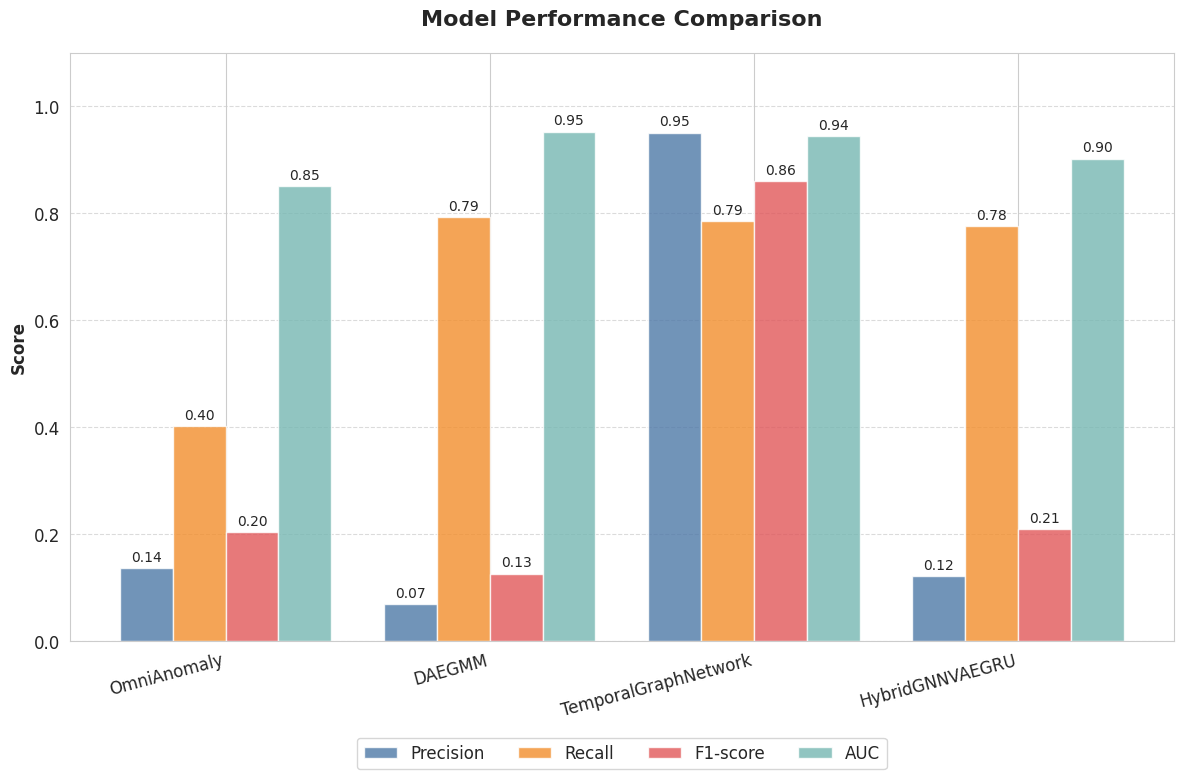

In [2]:
#  comparison chart
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for better visualization
sns.set_style("whitegrid")
plt.rcParams.update({'font.size': 12})

# Model names
models = ["OmniAnomaly", "DAEGMM", "TemporalGraphNetwork", "HybridGNNVAEGRU"]

# Performance metrics
precision = [0.1368, 0.0685, 0.9506, 0.1210]
recall = [0.4021, 0.7927, 0.7857, 0.7755]
f1_score = [0.2042, 0.1260, 0.8603, 0.2094]
auc = [0.8514, 0.9526, 0.9448, 0.9022]

# Metrics labels
metrics = ["Precision", "Recall", "F1-score", "AUC"]
values = [precision, recall, f1_score, auc]

# Convert data for plotting
x = np.arange(len(models))
width = 0.2  # Bar width

# Set up figure with better dimensions
fig, ax = plt.subplots(figsize=(12, 8))

# Color palette that's colorblind-friendly
colors = ["#4e79a7", "#f28e2c", "#e15759", "#76b7b2"]

# Plot bars for each metric
for i, (metric, val) in enumerate(zip(metrics, values)):
    bars = ax.bar(x + i * width, val, width, label=metric, color=colors[i], alpha=0.8)

    # Add value labels on top of each bar
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom',
                    fontsize=10)

# Formatting improvements
ax.set_ylim(0, 1.1)  # Set y-axis from 0 to 1.1 to accommodate labels
ax.set_xticks(x + width * (len(metrics) - 1) / 2)
ax.set_xticklabels(models, rotation=15, ha='right')
ax.set_ylabel("Score", fontweight='bold')
ax.set_title("Model Performance Comparison", fontsize=16, fontweight='bold', pad=20)

# Improved legend positioning
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=4)

# Add grid for better readability
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Tight layout for better spacing
plt.tight_layout()

# Save the graph (optional)
# plt.savefig('model_comparison.png', dpi=300, bbox_inches='tight')

# Show the graph
plt.show()

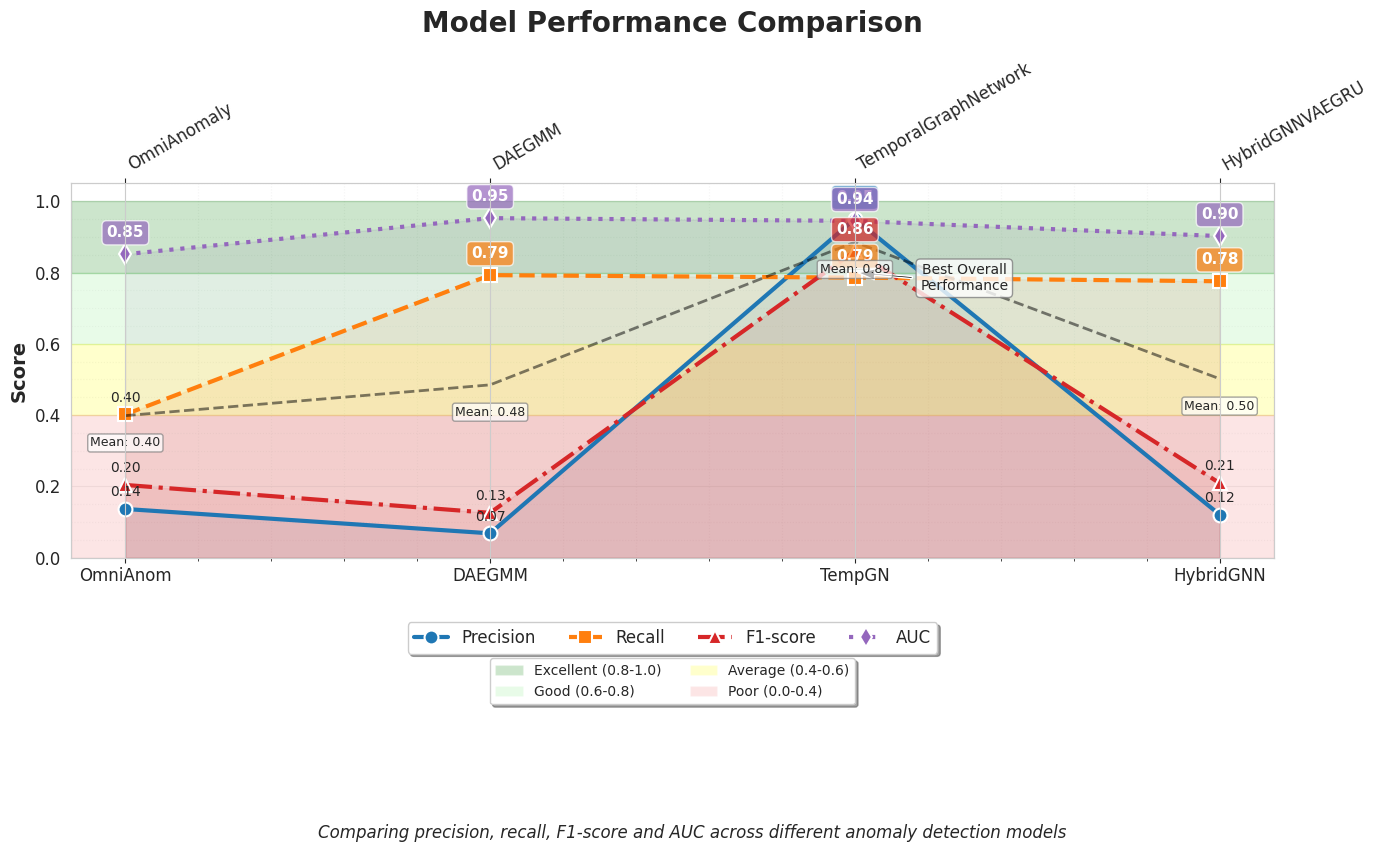

In [3]:
#  comparison chart from the ORIGINAL runs
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FormatStrFormatter

# Set style for better visualization
sns.set_style("whitegrid")
plt.rcParams.update({'font.size': 12, 'font.family': 'Arial'})

# Model names
models = ["OmniAnomaly", "DAEGMM", "TemporalGraphNetwork", "HybridGNNVAEGRU"]
model_short_names = ["OmniAnom", "DAEGMM", "TempGN", "HybridGNN"]

# Performance metrics
precision = [0.1368, 0.0685, 0.9506, 0.1210]
recall = [0.4021, 0.7927, 0.7857, 0.7755]
f1_score = [0.2042, 0.1260, 0.8603, 0.2094]
auc = [0.8514, 0.9526, 0.9448, 0.9022]

# Create data for plotting
x = np.arange(len(models))

# Set up figure
fig, ax = plt.subplots(figsize=(14, 9))

# Custom colormap
colors = ['#1f77b4', '#ff7f0e', '#d62728', '#9467bd']
markers = ['o', 's', '^', 'd']
linestyles = ['-', '--', '-.', ':']

# Plot lines for each metric
lines = []
for i, (metric, values, color, marker, ls) in enumerate(zip(
    ["Precision", "Recall", "F1-score", "AUC"],
    [precision, recall, f1_score, auc],
    colors, markers, linestyles)):

    line = ax.plot(x, values, marker=marker, linestyle=ls, linewidth=3,
                 label=metric, color=color, markersize=10,
                 markeredgecolor='white', markeredgewidth=1.5)
    lines.append(line[0])

    # Add shaded area under each line
    ax.fill_between(x, 0, values, alpha=0.1, color=color)

    # Add data labels with custom formatting
    for j, val in enumerate(values):
        if val >= 0.7:  # Highlight high value
            bbox_props = dict(boxstyle="round,pad=0.3", fc=color, ec="white", alpha=0.7)
            ax.annotate(f'{val:.2f}',
                        xy=(j, val),
                        xytext=(0, 10),
                        textcoords="offset points",
                        ha='center',
                        va='bottom',
                        fontsize=11,
                        fontweight='bold',
                        color='white',
                        bbox=bbox_props)
        else:
            ax.annotate(f'{val:.2f}',
                        xy=(j, val),
                        xytext=(0, 7),
                        textcoords="offset points",
                        ha='center',
                        va='bottom',
                        fontsize=10)

# Add performance zones
ax.axhspan(0.8, 1.0, alpha=0.2, color='green', label='Excellent')
ax.axhspan(0.6, 0.8, alpha=0.2, color='lightgreen', label='Good')
ax.axhspan(0.4, 0.6, alpha=0.2, color='yellow', label='Average')
ax.axhspan(0.0, 0.4, alpha=0.2, color='lightcoral', label='Poor')

# Add formatted tick labels for x-axis
ax.set_xticks(x)
ax.set_xticklabels(model_short_names)

# Add second x-axis with full model names
ax2 = ax.twiny()
ax2.set_xlim(ax.get_xlim())
ax2.set_xticks(x)
ax2.set_xticklabels(models, rotation=30, ha='left')

# Format y-axis
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score", fontweight='bold', fontsize=14)
ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))

# Add title and subtitle
ax.set_title("Model Performance Comparison", fontsize=20, fontweight='bold', pad=20)
plt.figtext(0.5, 0.01, "Comparing precision, recall, F1-score and AUC across different anomaly detection models",
           ha="center", fontsize=12, fontstyle='italic')

# Add annotations for key insights
best_model_idx = 2  # TemporalGraphNetwork
ax.annotate('Best Overall\nPerformance',
            xy=(best_model_idx, 0.8),
            xytext=(best_model_idx+0.3, 0.75),
            arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
            bbox=dict(boxstyle="round,pad=0.3", fc='white', ec="gray", alpha=0.8),
            fontsize=10, ha='center')

# Create custom legend
legend1 = ax.legend(lines, ["Precision", "Recall", "F1-score", "AUC"],
                   loc='upper center', bbox_to_anchor=(0.5, -0.15),
                   ncol=4, frameon=True, shadow=True, fontsize=12)

# Add a second legend for the performance zones
handles, labels = [], []
for color, zone in zip(['green', 'lightgreen', 'yellow', 'lightcoral'],
                      ['Excellent (0.8-1.0)', 'Good (0.6-0.8)', 'Average (0.4-0.6)', 'Poor (0.0-0.4)']):
    handles.append(plt.Rectangle((0,0), 1, 1, fc=color, alpha=0.2))
    labels.append(zone)

legend2 = ax.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, -0.25),
                   ncol=2, frameon=True, shadow=True, fontsize=10)
ax.add_artist(legend1)  # Add back the first legend

# Add grid with different styles
ax.grid(True, linestyle='-', alpha=0.3, which='major')
ax.grid(True, linestyle=':', alpha=0.2, which='minor')
ax.minorticks_on()

# Add mean performance line for each model
mean_performances = [(p + r + f + a)/4 for p, r, f, a in zip(precision, recall, f1_score, auc)]
ax.plot(x, mean_performances, 'k--', alpha=0.5, linewidth=2, label='Mean Performance')
for i, val in enumerate(mean_performances):
    ax.annotate(f'Mean: {val:.2f}',
                xy=(i, val),
                xytext=(0, -15),
                textcoords="offset points",
                ha='center',
                va='top',
                fontsize=9,
                bbox=dict(boxstyle="round,pad=0.2", fc='white', ec="gray", alpha=0.7))

# Add tight layout with adjusted spacing
plt.tight_layout(rect=[0, 0.05, 1, 0.95])

# Show the graph
plt.show()